# Pre-processing

In [1]:
import pandas as pd
import numpy as np
import sklearn
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [2]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\Admin\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

# Renaming the Unamed Column

In [5]:
df = pd.read_csv("Suicide_Detection (1).csv")

# Rename 'Unnamed' column
df = df.rename(columns={'Unnamed: 0': 'ID'})

# Drop rows with missing values in the 'class' column
df = df.dropna(subset=['class'])

In [6]:
df.head()

,ID,text,class
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide
1,3,Am I weird I don't get affected by compliments...,non-suicide
2,4,Finally 2020 is almost over... So I can never ...,non-suicide
3,8,i need helpjust help me im crying so hard,suicide
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide


In [7]:
df.isnull().sum()

ID       0
text     0
class    0
dtype: int64

# Cleaning along with other NLP Techniques for processing text: Tokenization, Lowercased-test, Filtered-text, Stopwords and Lemmatization

In [8]:
def clean_text(text):
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetic characters
    text = ' '.join(text.split())  # Remove extra whitespaces
    return text

# Apply the cleaning function to the 'text' column
df['cleaned_text'] = df['text'].apply(clean_text)

# Tokenization
df['tokenized_text'] = df['cleaned_text'].apply(word_tokenize)

# Lowercasing
df['lowercased_text'] = df['tokenized_text'].apply(lambda x: [word.lower() for word in x])

# Removing stopwords
stop_words = set(stopwords.words('english'))
df['filtered_text'] = df['lowercased_text'].apply(lambda x: [word for word in x if word not in stop_words])

# Lemmatization
lemmatizer = WordNetLemmatizer()
df['lemmatized_text'] = df['filtered_text'].apply(lambda x: [lemmatizer.lemmatize(word) for word in x])

In [9]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,..."
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin..."
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever..."
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]"
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y..."


# Encoding the target column into 1s and 0s

In [10]:
#Unique values in class
print(df['class'].unique())
# Create binary for class column
df['class_binary'] = df['class'].map({'suicide': 1, 'non-suicide': 0})

['suicide' 'non-suicide']


In [11]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text,class_binary
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,...",1
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin...",0
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever...",0
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]",1
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y...",1


In [12]:
df.isnull().sum()

ID                 0
text               0
class              0
cleaned_text       0
tokenized_text     0
lowercased_text    0
filtered_text      0
lemmatized_text    0
class_binary       0
dtype: int64

# Doing the TF-IDF Vectorization

In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Combine the lemmatized words back into sentences
df['processed_text'] = df['lemmatized_text'].apply(lambda x: ' '.join(x))

# Initialize the TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(max_features=5000)  # You can adjust max_features as needed

# Fit and transform the processed text
tfidf_matrix = tfidf_vectorizer.fit_transform(df['processed_text'])

# Convert the TF-IDF matrix to a DataFrame
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=tfidf_vectorizer.get_feature_names_out())

# Concatenate the TF-IDF DataFrame with the original DataFrame
df = pd.concat([df, tfidf_df], axis=1)


In [14]:
df.head()

,ID,text,class,cleaned_text,tokenized_text,lowercased_text,filtered_text,lemmatized_text,class_binary,processed_text,...,youtuber,youve,yr,yt,yum,zero,zoloft,zombie,zone,zoom
0,2,Ex Wife Threatening SuicideRecently I left my ...,suicide,Ex Wife Threatening SuicideRecently I left my ...,"[Ex, Wife, Threatening, SuicideRecently, I, le...","[ex, wife, threatening, suiciderecently, i, le...","[ex, wife, threatening, suiciderecently, left,...","[ex, wife, threatening, suiciderecently, left,...",1,ex wife threatening suiciderecently left wife ...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,3,Am I weird I don't get affected by compliments...,non-suicide,Am I weird I dont get affected by compliments ...,"[Am, I, weird, I, dont, get, affected, by, com...","[am, i, weird, i, dont, get, affected, by, com...","[weird, dont, get, affected, compliments, comi...","[weird, dont, get, affected, compliment, comin...",0,weird dont get affected compliment coming some...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,4,Finally 2020 is almost over... So I can never ...,non-suicide,Finally is almost over So I can never hear has...,"[Finally, is, almost, over, So, I, can, never,...","[finally, is, almost, over, so, i, can, never,...","[finally, almost, never, hear, bad, year, ever...","[finally, almost, never, hear, bad, year, ever...",0,finally almost never hear bad year ever swear ...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,8,i need helpjust help me im crying so hard,suicide,i need helpjust help me im crying so hard,"[i, need, helpjust, help, me, im, crying, so, ...","[i, need, helpjust, help, me, im, crying, so, ...","[need, helpjust, help, im, crying, hard]","[need, helpjust, help, im, cry, hard]",1,need helpjust help im cry hard,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,9,"I’m so lostHello, my name is Adam (16) and I’v...",suicide,Im so lostHello my name is Adam and Ive been s...,"[Im, so, lostHello, my, name, is, Adam, and, I...","[im, so, losthello, my, name, is, adam, and, i...","[im, losthello, name, adam, ive, struggling, y...","[im, losthello, name, adam, ive, struggling, y...",1,im losthello name adam ive struggling year im ...,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# Plotting the WordCloud for the Vectorized data

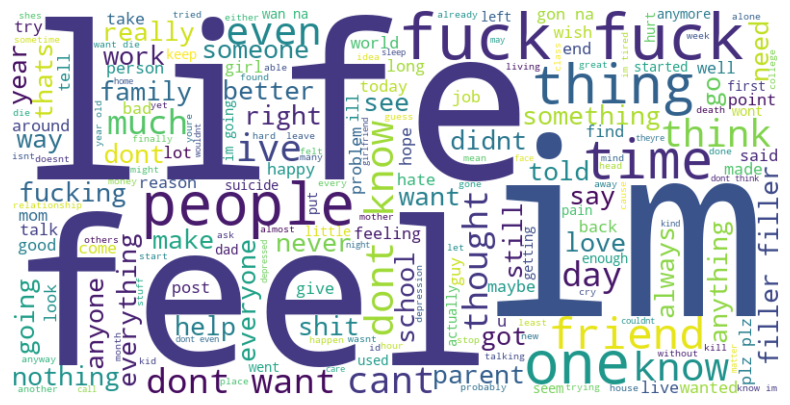

In [41]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame and 'processed_text' is the column containing preprocessed text
text_data = " ".join(df['processed_text'])

# Create a WordCloud object
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text_data)

# Display the Word Cloud using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.show()

# Training a basic Logistic Regression Model on the vectorized data

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Assuming 'class_binary' is the target variable
X = df.drop(['ID', 'text', 'class', 'class_binary', 'cleaned_text', 'tokenized_text', 'lowercased_text', 'filtered_text', 'lemmatized_text', 'processed_text'], axis=1)
y = df['class_binary']

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize and train a logistic regression model
model = LogisticRegression()
model.fit(X_train, y_train)

# Make predictions on the testing set
y_pred = model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
classification_rep = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy}")
print(f"Confusion Matrix:\n{conf_matrix}")
print(f"Classification Report:\n{classification_rep}")


Accuracy: 0.901595744680851
Confusion Matrix:
[[701  48]
 [100 655]]
Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.94      0.90       749
           1       0.93      0.87      0.90       755

    accuracy                           0.90      1504
   macro avg       0.90      0.90      0.90      1504
weighted avg       0.90      0.90      0.90      1504



# Creating a Recurrent Neural Network

In [16]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, SpatialDropout1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [34]:
from tensorflow.keras.callbacks import EarlyStopping
X_train, X_test, y_train, y_test = train_test_split(df['processed_text'], df['class_binary'], test_size=0.2, random_state=42)
max_words = 5000  # Maximum number of words to keep
max_len = 100  # Maximum length of sequences
tokenizer = Tokenizer(num_words=max_words, split=' ')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Encode labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Build the RNN model
embedding_dim = 50  # Dimension of word embeddings
model = Sequential()
model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len))
model.add(SpatialDropout1D(0.2))
model.add(LSTM(80))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
# Train the model
epochs = 5
batch_size = 32
#model.fit(X_train_pad, y_train_encoded, epochs=epochs, batch_size=batch_size, validation_data=(X_test_pad, y_test_encoded))
history = model.fit(X_train_pad, y_train_encoded, epochs=epochs, batch_size=batch_size,
                    validation_data=(X_test_pad, y_test_encoded), callbacks=[early_stopping])
# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_pad, y_test_encoded)
print(f"Test Accuracy: {accuracy}")

Epoch 1/5
188/188 [==============================] - 18s 84ms/step - loss: 0.3993 - accuracy: 0.8270 - val_loss: 0.2636 - val_accuracy: 0.9029
Epoch 2/5
188/188 [==============================] - 16s 83ms/step - loss: 0.2024 - accuracy: 0.9257 - val_loss: 0.2892 - val_accuracy: 0.8923
Epoch 3/5
188/188 [==============================] - 15s 82ms/step - loss: 0.1443 - accuracy: 0.9506 - val_loss: 0.2957 - val_accuracy: 0.8963
Epoch 4/5
47/47 [==============================] - 1s 29ms/step - loss: 0.2636 - accuracy: 0.9029
Test Accuracy: 0.9029255509376526


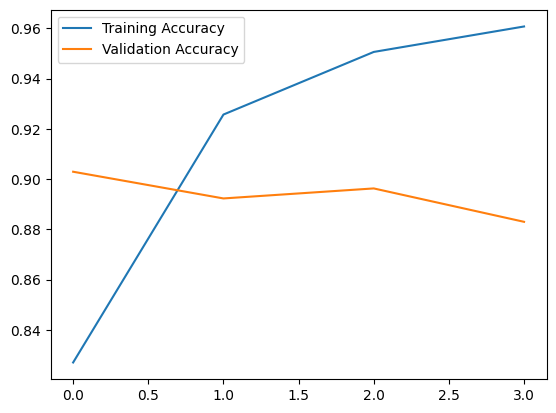

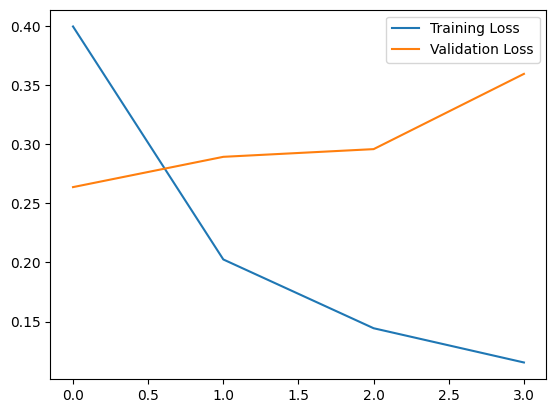

In [35]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

# Creating a bi-directional LSTM 

In [36]:
from tensorflow.keras.layers import Bidirectional
X_train, X_test, y_train, y_test = train_test_split(df['processed_text'], df['class_binary'], test_size=0.2, random_state=42)
max_words = 5000  # Maximum number of words to keep
max_len = 100  # Maximum length of sequences
tokenizer = Tokenizer(num_words=max_words, split=' ')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Encode labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Build the Bidirectional LSTM model
model = Sequential()
model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len))
model.add(SpatialDropout1D(0.5))
model.add(Bidirectional(LSTM(80, dropout=0.5)))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model
epochs = 5
batch_size = 32
history = model.fit(X_train_pad, y_train_encoded, epochs=epochs, batch_size=batch_size,
                    validation_data=(X_test_pad, y_test_encoded), callbacks=[early_stopping])

# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_pad, y_test_encoded)
print(f"Test Accuracy: {accuracy}")


Epoch 1/5
188/188 [==============================] - 40s 165ms/step - loss: 0.4428 - accuracy: 0.7965 - val_loss: 0.2931 - val_accuracy: 0.8890
Epoch 2/5
188/188 [==============================] - 28s 149ms/step - loss: 0.2649 - accuracy: 0.8951 - val_loss: 0.2423 - val_accuracy: 0.9102
Epoch 3/5
188/188 [==============================] - 28s 148ms/step - loss: 0.2072 - accuracy: 0.9212 - val_loss: 0.2629 - val_accuracy: 0.9009
Epoch 4/5
188/188 [==============================] - 27s 146ms/step - loss: 0.1723 - accuracy: 0.9378 - val_loss: 0.2692 - val_accuracy: 0.9043
Epoch 5/5
47/47 [==============================] - 2s 47ms/step - loss: 0.2423 - accuracy: 0.9102
Test Accuracy: 0.9102393388748169


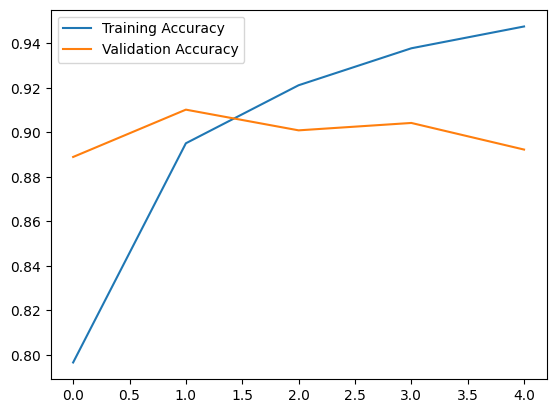

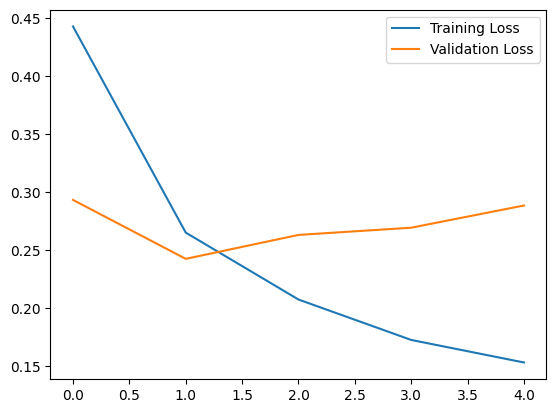

In [37]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

# Creating a Convolution Neural Network 

In [46]:
from tensorflow.keras.layers import Embedding, Conv1D, GlobalMaxPooling1D, Dense, SpatialDropout1D
from tensorflow.keras.layers import Dropout
X_train, X_test, y_train, y_test = train_test_split(df['processed_text'], df['class_binary'], test_size=0.2, random_state=42)

max_words = 5000  # Maximum number of words to keep
max_len = 100  # Maximum length of sequences

tokenizer = Tokenizer(num_words=max_words, split=' ')
tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(X_train_seq, maxlen=max_len)
X_test_pad = pad_sequences(X_test_seq, maxlen=max_len)

# Encode labels
label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Build the CNN model
embedding_dim = 100  # Dimension of word embeddings
model = Sequential()
model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=max_len))
model.add(Conv1D(128, 5, activation='relu'))
model.add(GlobalMaxPooling1D())
model.add(Dropout(0.5))
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Train the model
epochs = 5
batch_size = 32
history = model.fit(X_train_pad, y_train_encoded, epochs=epochs, batch_size=batch_size,
                    validation_data=(X_test_pad, y_test_encoded), callbacks=[early_stopping])

# Evaluate the model on the test set
loss, accuracy = model.evaluate(X_test_pad, y_test_encoded)
print(f"Test Accuracy: {accuracy}")

Epoch 1/5
188/188 [==============================] - 16s 68ms/step - loss: 0.4735 - accuracy: 0.7758 - val_loss: 0.2949 - val_accuracy: 0.8863
Epoch 2/5
188/188 [==============================] - 11s 59ms/step - loss: 0.2391 - accuracy: 0.9119 - val_loss: 0.2589 - val_accuracy: 0.8956
Epoch 3/5
188/188 [==============================] - 11s 57ms/step - loss: 0.1571 - accuracy: 0.9451 - val_loss: 0.2807 - val_accuracy: 0.8930
Epoch 4/5
188/188 [==============================] - 11s 60ms/step - loss: 0.1126 - accuracy: 0.9624 - val_loss: 0.3248 - val_accuracy: 0.8816
Epoch 5/5
47/47 [==============================] - 1s 15ms/step - loss: 0.2589 - accuracy: 0.8956
Test Accuracy: 0.8956117033958435


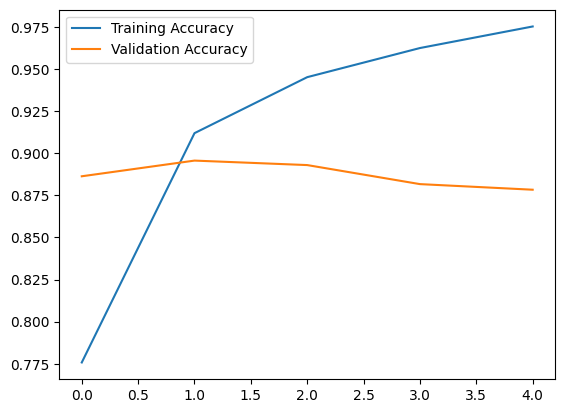

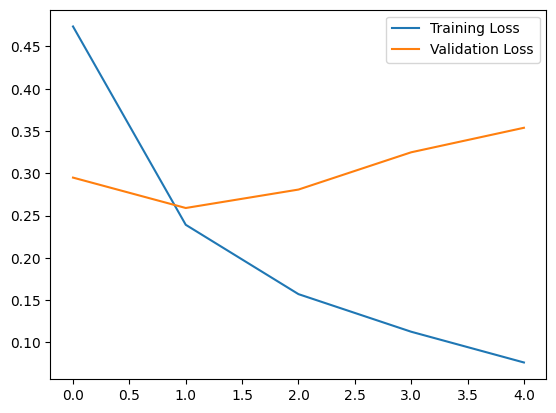

In [47]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()

# Plot training and validation loss
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()